# Exercise 2 — Computer Vision: Image Blending Using OpenCV
**Trainee:** Akhilesh Jaiswal | **Program:** GOT-A

**Objective:** Load two images with OpenCV, make their dimensions match, blend them with `cv2.addWeighted`, and display/save the originals and blend.

**Concepts:** OpenCV (`cv2`) is an image-processing library. An image is represented as an array. `addWeighted` combines two images using `output = image1 × alpha + image2 × beta + gamma`.

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
IMAGE_DIR = PROJECT_DIR / "images"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

image1 = cv2.imread(str(IMAGE_DIR / "Exercise2_Image1.jpg"))
image2 = cv2.imread(str(IMAGE_DIR / "Exercise2_Image2.jpg"))
if image1 is None or image2 is None:
    raise FileNotFoundError("Check that both sample images are inside the images folder.")
print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)

Image 1 shape: (400, 640, 3)
Image 2 shape: (400, 640, 3)


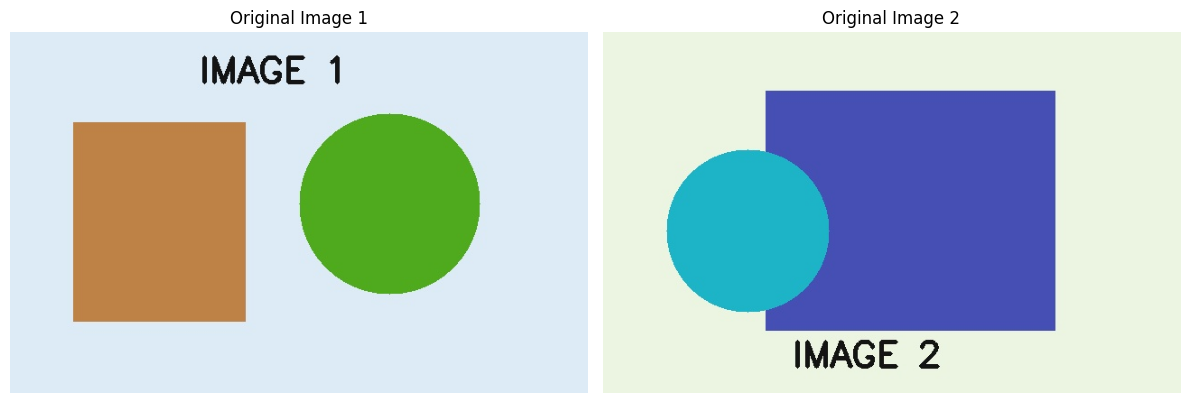

In [3]:
# Display both original images

image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("Original Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Original Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

## Task 2.1 — Match image dimensions
Both images must have the same height, width and channel count before blending.

In [5]:
height, width = image1.shape[:2]
if image2.shape[:2] != image1.shape[:2]:
    image2 = cv2.resize(image2, (width, height))
print("Matching shapes:", image1.shape == image2.shape)

Matching shapes: True


## Task 2.2 — Weighted blending
Here each image contributes 50%; gamma is zero (no extra brightness offset).

In [6]:
blended = cv2.addWeighted(image1, 0.5, image2, 0.5, 0)
cv2.imwrite(str(IMAGE_DIR / "Exercise2_Blended.jpg"), blended)
print("Blended image saved.")

Blended image saved.


## Task 2.3 — Display originals and blended output
OpenCV uses BGR channels; Matplotlib expects RGB, so convert before displaying.

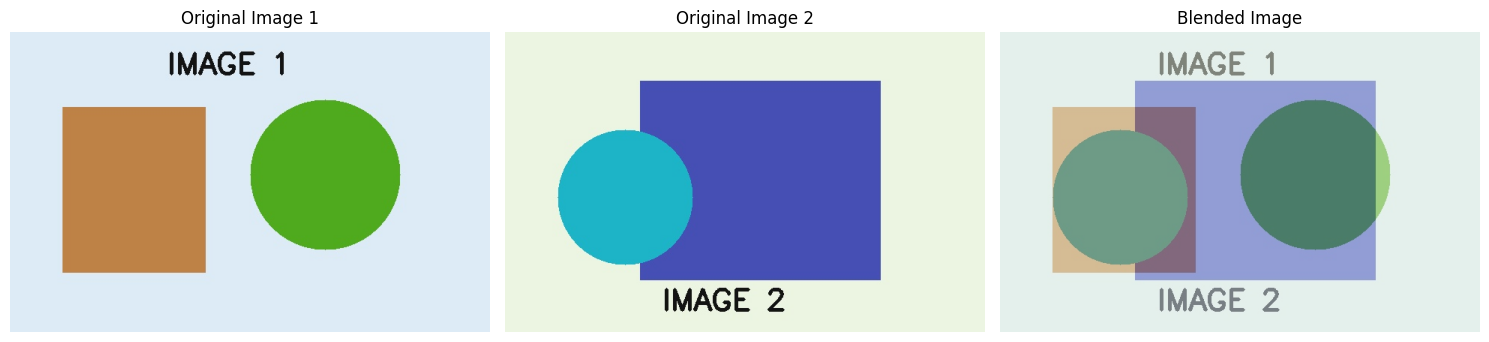

In [7]:
triplet = [
    ("Original Image 1", cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)),
    ("Original Image 2", cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)),
    ("Blended Image", cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, im) in zip(axes, triplet):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Exercise2_Three_Images.png", dpi=150)
plt.show()

## Result
Loaded two images, checked dimensions, blended at 50:50 and displayed all three images.

**Deliverables:** two originals and `Exercise2_Blended.jpg` in `images/`, plus comparison figure in `outputs/`.